# Case study: Kelmarsh 1 wind turbine, 2019

A qlPCA analysis of ten-minute SCADA data of one Senvion MM92 turbine at Kelmarsh wind farm (UK). The data set
passed the screening criterion of [`README.md`](README.md) (p = 2, out-of-sample gain of qlPCA over PCA ≥ 5 points).

* Data: Plumley, C. & Takeuchi, R., *Kelmarsh wind farm data*, Zenodo, record 16807551 (2025-08-12),
  doi:10.5281/zenodo.16807551, CC-BY-4.0; turbine Kelmarsh 1, year 2019; downloaded at run time.
* Filtering and sample: as in [`screening.py`](screening.py) (stoppages, alarms and communication losses removed;
  `Power <= 0` removed; missing values removed; 2000 records drawn with `numpy.random.default_rng(2026)`). With this
  rule March 2019 has no records (section 1).
* Turbine data: Senvion, *MM92 — Technical data*, product page of senvion.com (no longer online), archived copy of
  2020-04-02: [https://web.archive.org/web/20200402094941/https://www.senvion.com/senvion-uk/en/wind-turbines/mm92/](https://web.archive.org/web/20200402094941/https://www.senvion.com/senvion-uk/en/wind-turbines/mm92/). Quoted values: nominal power 2,050 kW; cut-in wind speed 3 m/s; nominal wind
  speed 12.5 m/s; cut-out wind speed 24 m/s; rotor speed 7.5 – 15 1/min (+12.5 %). `Kelmarsh_WT_static.csv`
  (Zenodo) gives rated power 2050 kW, hub height 78.5 m, rotor diameter 92 m, and no wind or rotor speeds.
* The page gives a rotor-speed *range*, not a value called "nominal rotor speed"; 15 rpm, the upper end of the
  range, is used below as the rotor-speed limit. **No value for the pitch angle at which pitching starts is given**
  by either source.
* Method: `qlpca` (Lavado & Calapez 2011, `lavado2011ijam`; Lavado 2012, `lavado2012phd`), default mode.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

HERE = Path.cwd()
sys.path.insert(0, str(HERE))
import screening as s
from qlpca import QLPCA, ExtrapolationWarning
from qlpca.diagnostics import piecewise_loadings
from qlpca.plots import set_style, transformation_plots, biplot, BLUE, ORANGE, INK, INK2, GRID
from qlpca.splines import interior_knots

set_style()
pd.set_option("display.precision", 4)
RES = HERE / "results"
RES.mkdir(exist_ok=True)


def save(fig, stem):
    for ext in ("pdf", "png"):
        fig.savefig(RES / f"{stem}.{ext}", bbox_inches="tight", dpi=150,
                    metadata={"CreationDate": None} if ext == "pdf" else None)


# turbine data (Senvion MM92 product page, archived 2020-04-02)
CUT_IN, RATED_WIND, RATED_POWER = 3.0, 12.5, 2050.0
ROTOR_MIN, ROTOR_MAX = 7.5, 15.0
P = 2

## 1. Data

In [2]:
df, info = s.load_kelmarsh()
data = s.sample(df, info, keep_time=True)
print({k: info[k] for k in ("records", "removed_status_events", "removed_power_le_0", "removed_missing",
                            "records_after_filtering", "sample_first", "sample_last")})
print("correlation rotor_speed - generator_speed:", round(data["rotor_speed"].corr(data["generator_speed"]), 6))
time = data.pop("time")
X = data.drop(columns="generator_speed")
VARS = list(X.columns)
print(len(VARS), "variables:", VARS)
X.describe().T

{'records': 52560, 'removed_status_events': 12387, 'removed_power_le_0': 3283, 'removed_missing': 0, 'records_after_filtering': 36890, 'sample_first': '2019-01-01 08:20:00', 'sample_last': '2019-12-31 19:30:00'}
correlation rotor_speed - generator_speed: 0.999982
8 variables: ['wind_speed', 'power', 'rotor_speed', 'pitch_angle', 'nacelle_temp', 'generator_temp', 'gearbox_temp', 'ambient_temp']


,count,mean,std,min,25%,50%,75%,max
wind_speed,2000.0,6.5412,2.2710,2.0022,4.9429,6.3118,7.8165,19.7303
power,2000.0,683.3956,567.0099,0.0240,229.3298,513.7435,988.5741,2069.7420
rotor_speed,2000.0,11.6281,2.6072,1.9960,9.2636,11.6384,14.0790,15.2653
pitch_angle,2000.0,0.8531,3.1080,0.0000,0.0000,0.0000,0.2706,38.8120
nacelle_temp,2000.0,22.1394,5.2291,6.6000,18.8894,22.5438,25.6487,38.7800
generator_temp,2000.0,63.3240,5.6814,37.4056,60.2781,62.5130,64.3931,101.7500
gearbox_temp,2000.0,54.6735,3.5758,34.1694,52.4273,55.2688,57.5831,59.9925
ambient_temp,2000.0,12.0824,6.0103,0.2075,7.2350,11.4938,16.3300,36.2750


`generator_speed` is removed: its correlation with `rotor_speed` is 1.0000 to four decimals (the generator is
driven through a gearbox), so it duplicates `rotor_speed`. Eight variables remain.

**Coverage by month.** The filtering rule of the screening (fixed before the analysis) removes every record that
overlaps a Warning event. The table shows the records per month before and after filtering, and the longest
events used by the filter.

In [3]:
import zipfile
z = zipfile.ZipFile(s.CACHE / s.KELMARSH["file"])
raw_t = pd.to_datetime(pd.read_csv(z.open(next(n for n in z.namelist() if n.startswith("Turbine_Data_Kelmarsh_1_"))),
                                   skiprows=9, usecols=[0], encoding="latin-1").iloc[:, 0])
st = pd.read_csv(z.open(next(n for n in z.namelist() if n.startswith("Status_Kelmarsh_1_"))), skiprows=9)
st = st[st.Status.isin(["Stop", "Warning", "Communication"])].copy()
st["start"], st["end"] = pd.to_datetime(st["Timestamp start"]), pd.to_datetime(st["Timestamp end"])
st["duration"] = st.end - st.start
display(pd.DataFrame({"records in the year": raw_t.dt.month.value_counts().sort_index(),
                      "after filtering": df.time.dt.month.value_counts().reindex(range(1, 13), fill_value=0),
                      "in the sample": time.dt.month.value_counts().reindex(range(1, 13), fill_value=0)}).T)
st.sort_values("duration", ascending=False)[["start", "end", "duration", "Status", "Message"]].head(4)

,1,2,3,4,5,6,7,8,9,10,11,12
records in the year,4464,4032,4464,4320,4464,4320,4464,4464,4320,4464,4320,4464
after filtering,4049,3215,0,701,1153,3835,3760,4133,3866,4229,3684,4265
in the sample,214,159,0,37,60,209,212,219,213,240,189,248


,start,end,duration,Status,Message
1435,2019-04-09 10:09:03,2019-05-21 10:06:24,41 days 23:57:21,Warning,Oil filter gear choked
573,2019-02-24 16:46:28,2019-04-04 12:35:45,38 days 19:49:17,Warning,Oil filter gear choked
2308,2019-05-05 03:28:29,2019-05-21 10:13:26,16 days 06:44:57,Communication,Data communication unavailable
2766,2019-05-28 20:55:45,2019-05-30 07:34:04,1 days 10:38:19,Warning,Oil filter gear choked


## 2. Operating regimes

Regimes by wind speed, from the Senvion data: **below cut-in** (< 3 m/s; records with positive power remain after
filtering), **partial load** (3 – 12.5 m/s) and **full load** (≥ 12.5 m/s). Horizontal lines: nominal power
2050 kW; rotor-speed range 7.5 – 15 rpm.

wind_speed
below cut-in (< 3 m/s)           63
partial load (3 - 12.5 m/s)    1911
full load (>= 12.5 m/s)          26
rotor speed in partial load: 1st percentile 7.36 rpm, maximum 15.25 rpm; records below 7.5 rpm: 36 (all regimes), above 15 rpm: 260


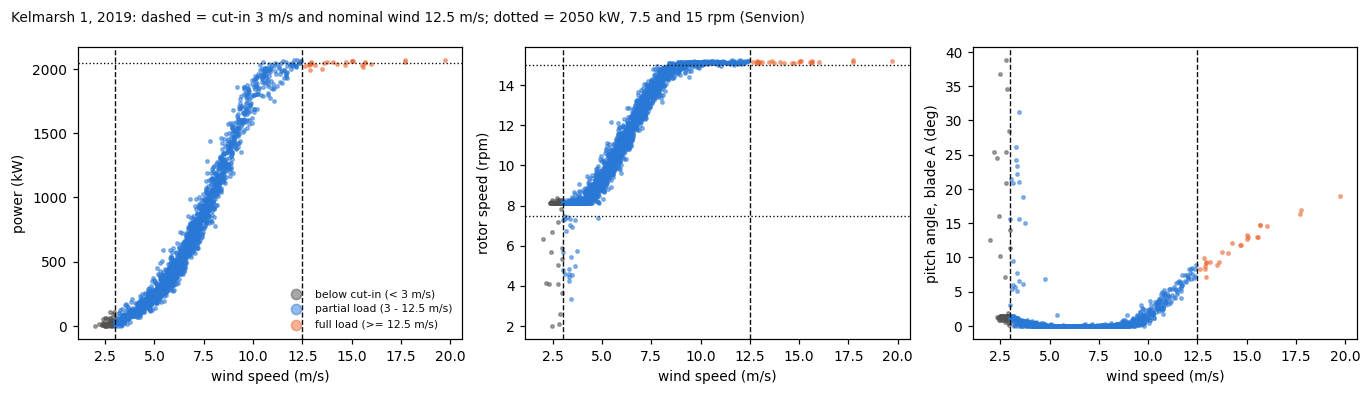

In [4]:
REGIMES = ["below cut-in (< 3 m/s)", "partial load (3 - 12.5 m/s)", "full load (>= 12.5 m/s)"]
regime = pd.Series(pd.cut(X.wind_speed, [-np.inf, CUT_IN, RATED_WIND, np.inf], right=False, labels=REGIMES))
RCOL = dict(zip(REGIMES, [INK2, BLUE, ORANGE]))
print(regime.value_counts().reindex(REGIMES).to_string())
pl_rotor = X.rotor_speed[(X.wind_speed >= CUT_IN) & (X.wind_speed < RATED_WIND)]
print(f"rotor speed in partial load: 1st percentile {pl_rotor.quantile(0.01):.2f} rpm, maximum {pl_rotor.max():.2f} rpm; "
      f"records below 7.5 rpm: {(X.rotor_speed < ROTOR_MIN).sum()} (all regimes), above 15 rpm: {(X.rotor_speed > ROTOR_MAX).sum()}")

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.6))
for ax, (col, lab) in zip(axes, [("power", "power (kW)"), ("rotor_speed", "rotor speed (rpm)"),
                                  ("pitch_angle", "pitch angle, blade A (deg)")]):
    for r in REGIMES:
        sel = regime == r
        ax.scatter(X.wind_speed[sel], X[col][sel], s=5, alpha=0.5, color=RCOL[r], label=r)
    for v in (CUT_IN, RATED_WIND):
        ax.axvline(v, color=INK, lw=0.9, ls="--")
    if col == "power":
        ax.axhline(RATED_POWER, color=INK, lw=0.9, ls=":")
    if col == "rotor_speed":
        for v in (ROTOR_MIN, ROTOR_MAX):
            ax.axhline(v, color=INK, lw=0.9, ls=":")
    ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel(lab)
axes[0].legend(fontsize=7, frameon=False, markerscale=3)
fig.suptitle("Kelmarsh 1, 2019: dashed = cut-in 3 m/s and nominal wind 12.5 m/s; dotted = 2050 kW, 7.5 and 15 rpm (Senvion)",
             fontsize=9, x=0.01, ha="left")
fig.tight_layout()
save(fig, "case_operating_regimes")
plt.show()

## 3. Models (p = 2)

* **PCA**: `QLPCA(n_knots=0)`.
* **qlPCA, percentile knots**: `QLPCA(n_knots=2)` (knots at the 33rd and 67th percentiles of the training data).
* **qlPCA, physical knots** (`knots=` explicit): wind speed 3 and 12.5 m/s; power 2050 kW; rotor speed 7.5 and
  15 rpm; pitch angle none (the only regime boundary, 0°, is the minimum of the data: 58 % of the records are at
  0°; no other pitch value is given by the sources); temperatures at the 33rd and 67th percentiles of the
  training data.
* Both qlPCA models also with `monotone=True`.

In-sample VAF: fit on the 2000 records. Out-of-sample VAF: 5 contiguous time blocks, test rows clipped to the
training range, `100 ||F_test V||² / ||F_test||²` (criterion of `screening.py`). The gain over PCA is computed
**block by block** (paired) and summarised by its mean and standard error.

In [5]:
PHYSICAL = {"wind_speed": [CUT_IN, RATED_WIND], "power": [RATED_POWER], "rotor_speed": [ROTOR_MIN, ROTOR_MAX],
            "pitch_angle": []}


def physical_knots(Xtr):
    Xtr = pd.DataFrame(Xtr, columns=VARS)
    return [np.asarray(PHYSICAL[v], float) if v in PHYSICAL else interior_knots(Xtr[v].to_numpy(), 2) for v in VARS]


SPECS = {
    "PCA": lambda Xtr: dict(n_knots=0),
    "qlPCA, percentile knots": lambda Xtr: dict(n_knots=2),
    "qlPCA, percentile knots, monotone": lambda Xtr: dict(n_knots=2, monotone=True),
    "qlPCA, physical knots": lambda Xtr: dict(knots=physical_knots(Xtr)),
    "qlPCA, physical knots, monotone": lambda Xtr: dict(knots=physical_knots(Xtr), monotone=True),
}


def fit(name, Xtr, p=P):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        return QLPCA(n_components=p, random_state=0, **SPECS[name](np.asarray(Xtr))).fit(Xtr)


A = X.to_numpy()
blocks = np.array_split(np.arange(len(A)), 5)
oos = {name: [] for name in SPECS}
for te in blocks:
    tr = np.setdiff1d(np.arange(len(A)), te)
    for name in SPECS:
        oos[name].append(s.oos_vaf(A, fit(name, A[tr]), A[te], A[tr]))
oos = {k: np.array(v) for k, v in oos.items()}
models = {name: fit(name, X) for name in SPECS}

rows = []
for name in SPECS:
    gain = oos[name] - oos["PCA"]
    rows.append({"model": name, "VAF in sample": models[name].vaf_.sum(), "VAF out of sample": oos[name].mean(),
                 "se (out of sample)": oos[name].std(ddof=1) / np.sqrt(5),
                 "paired gain over PCA": gain.mean() if name != "PCA" else np.nan,
                 "se (paired gain)": gain.std(ddof=1) / np.sqrt(5) if name != "PCA" else np.nan})
vaf_table = pd.DataFrame(rows).set_index("model")
vaf_table.to_csv(RES / "case_vaf.csv", float_format="%.4f", lineterminator="\n")
pd.DataFrame(oos, index=[f"block {i + 1}" for i in range(5)]).to_csv(RES / "case_vaf_blocks.csv", float_format="%.4f",
                                                                     lineterminator="\n")
vaf_table

,VAF in sample,VAF out of sample,se (out of sample),paired gain over PCA,se (paired gain)
model,,,,,
PCA,70.7512,71.0428,3.5094,NaN,NaN
"qlPCA, percentile knots",79.6026,79.5178,1.9003,8.4750,1.7711
"qlPCA, percentile knots, monotone",77.3197,76.7355,2.9913,5.6927,0.6953
"qlPCA, physical knots",74.3038,74.0076,3.2981,2.9648,0.8272
"qlPCA, physical knots, monotone",73.8871,73.6138,3.4203,2.5710,0.7283


In [6]:
pd.DataFrame(oos, index=[f"block {i + 1} ({time.iloc[b[0]]:%Y-%m-%d} to {time.iloc[b[-1]]:%Y-%m-%d})"
                         for i, b in enumerate(blocks)]).round(2)

,PCA,"qlPCA, percentile knots","qlPCA, percentile knots, monotone","qlPCA, physical knots","qlPCA, physical knots, monotone"
block 1 (2019-01-01 to 2019-04-07),75.54,82.40,81.26,79.02,78.69
block 2 (2019-04-07 to 2019-07-19),59.56,74.75,67.93,64.91,64.02
block 3 (2019-07-19 to 2019-09-11),74.32,80.91,79.17,74.93,74.98
block 4 (2019-09-11 to 2019-11-08),66.71,75.34,71.60,68.39,67.80
block 5 (2019-11-08 to 2019-12-31),79.09,84.19,83.71,82.79,82.58


## 4. V-shaped transformations

With percentile knots, `wind_speed`, `power` and `rotor_speed` have V-shaped transformations (screening). Below:
the records on the **descending** segment of each (slope of f_j negative), how many there are, in which months, and
the values of the other variables there compared with the remaining records. The data are reported as they are.

In [7]:
mp = models["qlPCA, percentile knots"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    pl_p = piecewise_loadings(mp, X)
desc = {}
for v in ("wind_speed", "power", "rotor_speed"):
    j = VARS.index(v)
    seg = [k for k, sg in enumerate(pl_p[j]["slope_sign"]) if sg < 0]
    e = pl_p[j]["edges"]
    mask = np.zeros(len(X), bool)
    for k in seg:
        mask |= (X[v] >= e[k]).to_numpy() & (X[v] <= e[k + 1]).to_numpy()
    desc[v] = mask
    print(f"{v}: descending segment(s) {[(round(e[k], 2), round(e[k + 1], 2)) for k in seg]}; "
          f"{mask.sum()} of {len(X)} records ({mask.mean():.0%})")

wind_speed: descending segment(s) [(np.float64(2.0), np.float64(5.39))]; 660 of 2000 records (33%)
power: descending segment(s) [(np.float64(0.02), np.float64(310.77))]; 660 of 2000 records (33%)
rotor_speed: descending segment(s) [(np.float64(2.0), np.float64(10.07))]; 659 of 2000 records (33%)


In [8]:
months = pd.DataFrame({v: pd.Series(time[m].dt.month).value_counts().reindex(range(1, 13), fill_value=0)
                       for v, m in desc.items()})
months["all records"] = time.dt.month.value_counts().reindex(range(1, 13), fill_value=0)
months.index.name = "month"
months.T

month,1,2,3,4,5,6,7,8,9,10,11,12
wind_speed,78,29,0,15,19,73,104,64,69,91,70,48
power,72,30,0,16,17,77,108,66,72,91,67,44
rotor_speed,74,30,0,16,18,76,106,64,71,91,68,45
all records,214,159,0,37,60,209,212,219,213,240,189,248


In [9]:
comp = {}
for v, m in desc.items():
    comp[(v, "descending segment")] = X[m].median()
    comp[(v, "other records")] = X[~m].median()
pd.DataFrame(comp).round(2)

wind_speed                            power  \
               descending segment other records descending segment   
wind_speed                   4.35          7.26               4.35   
power                      150.61        808.31             150.61   
rotor_speed                  8.49         13.36               8.49   
pitch_angle                  0.07          0.00               0.07   
nacelle_temp                24.18         21.53              24.28   
generator_temp              61.27         62.98              61.29   
gearbox_temp                56.59         54.52              56.59   
ambient_temp                12.81         10.87              13.07   

                                    rotor_speed                
               other records descending segment other records  
wind_speed              7.26               4.35          7.26  
power                 808.31             150.67        808.29  
rotor_speed            13.36               8.50         13.35  
pitch_angle             0.00               0.07          0.00  
nacelle_temp           21.49              24.24         21.51  
generator_temp         63.01              61.30         63.02  
gearbox_temp           54.53              56.54         54.54  
ambient_temp           10.70              12.87         10.73

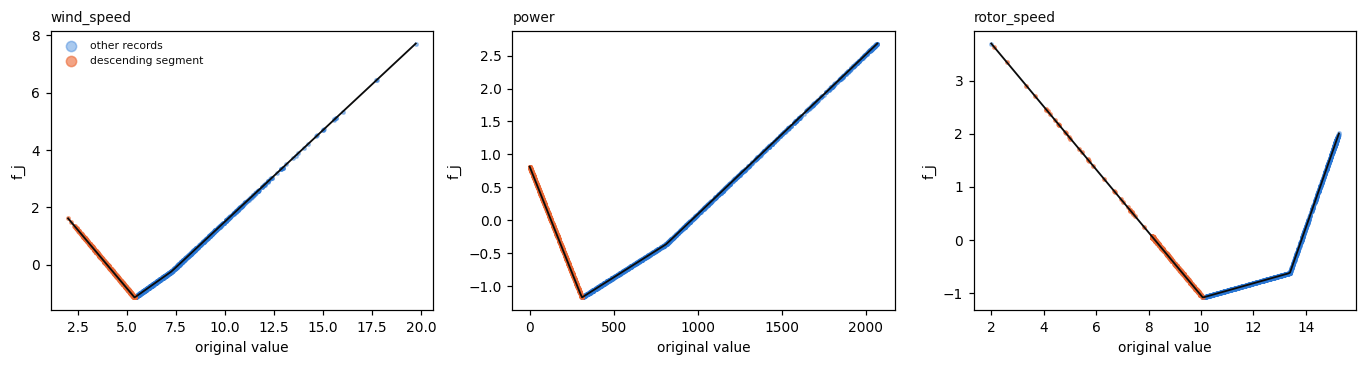

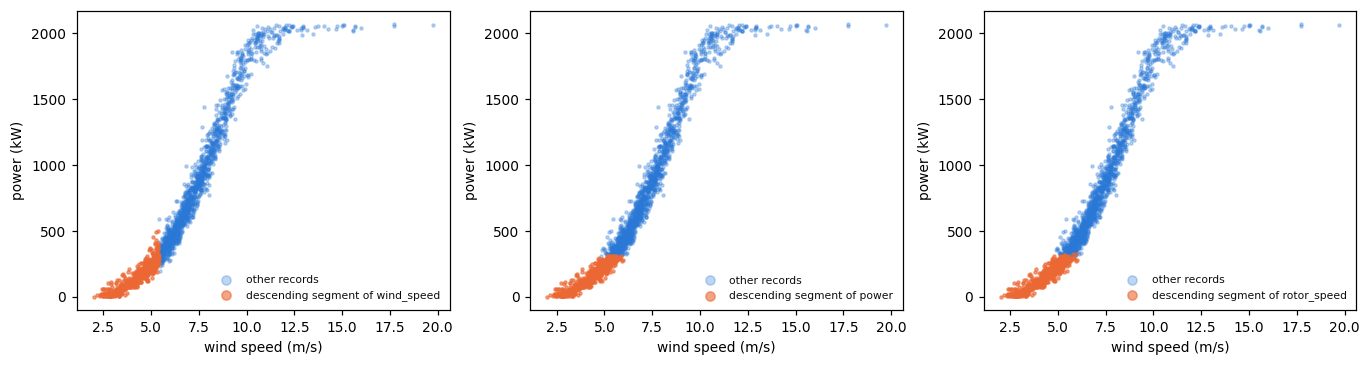

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, v in zip(axes, desc):
    j = VARS.index(v)
    x, f = mp.variable_transformation(j)
    ax.plot(x, f, color=INK, lw=1.2)
    m = desc[v]
    ax.scatter(X[v][~m], mp.transformed_[~m, j], s=5, color=BLUE, alpha=0.4, label="other records")
    ax.scatter(X[v][m], mp.transformed_[m, j], s=5, color=ORANGE, alpha=0.6, label="descending segment")
    ax.set_title(v, fontsize=9, loc="left"); ax.set_xlabel("original value"); ax.set_ylabel("f_j")
axes[0].legend(fontsize=7, frameon=False, markerscale=3)
fig.tight_layout()
save(fig, "case_v_shapes")
plt.show()

# same records in the operating-curve plots
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.4))
for ax, v in zip(axes, desc):
    m = desc[v]
    ax.scatter(X.wind_speed[~m], X.power[~m], s=4, color=BLUE, alpha=0.3, label="other records")
    ax.scatter(X.wind_speed[m], X.power[m], s=4, color=ORANGE, alpha=0.6, label=f"descending segment of {v}")
    ax.set_xlabel("wind speed (m/s)"); ax.set_ylabel("power (kW)"); ax.legend(fontsize=7, frameon=False, markerscale=3)
fig.tight_layout()
save(fig, "case_v_shapes_power_curve")
plt.show()

In [11]:
mf = models["qlPCA, physical knots"]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    pl_f = piecewise_loadings(mf, X)
print("slope signs of f_j by segment, physical knots:")
for j, v in enumerate(VARS):
    print(f"  {v:15s} edges {np.round(pl_f[j]['edges'], 2).tolist()}  signs {pl_f[j]['slope_sign'].astype(int).tolist()}")

slope signs of f_j by segment, physical knots:
  wind_speed      edges [2.0, 3.0, 12.5, 19.73]  signs [-1, 1, 1]
  power           edges [0.02, 2050.0, 2069.74]  signs [1, 1]
  rotor_speed     edges [2.0, 7.5, 15.0, 15.27]  signs [-1, 1, 1]
  pitch_angle     edges [-0.0, 38.81]  signs [1]
  nacelle_temp    edges [6.6, 20.34, 24.6, 38.78]  signs [1, 1, 1]
  generator_temp  edges [37.41, 60.96, 63.85, 101.75]  signs [1, 1, 1]
  gearbox_temp    edges [34.17, 53.38, 56.79, 59.99]  signs [1, 1, 1]
  ambient_temp    edges [0.21, 8.71, 14.81, 36.27]  signs [1, 1, 1]


## 5. Piecewise loadings by regime (physical knots)

For each variable and each segment between its knots: number of records and the correlation of the two components
with the original variable on that segment (thesis eqs. 3.7–3.8). For `wind_speed` the segments are the operating
regimes of section 2.

In [12]:
rows = []
for j, v in enumerate(VARS):
    d = pl_f[j]
    for k in range(len(d["slope_sign"])):
        rows.append({"variable": v, "segment": f"[{d['edges'][k] + 0.0:.2f}, {d['edges'][k + 1] + 0.0:.2f}]", "n": int(d["n"][k]),
                     "slope sign": int(d["slope_sign"][k]), "loading 1": d["loadings"][k][0], "loading 2": d["loadings"][k][1]})
pl_table = pd.DataFrame(rows)
pl_table.to_csv(RES / "case_piecewise_loadings.csv", index=False, float_format="%.4f", lineterminator="\n")
pl_table

,variable,segment,n,slope sign,loading 1,loading 2
0,wind_speed,"[2.00, 3.00]",63,-1,-0.4480,-0.1046
1,wind_speed,"[3.00, 12.50]",1911,1,0.9233,0.0704
2,wind_speed,"[12.50, 19.73]",26,1,0.8065,0.6222
3,power,"[0.02, 2050.00]",1982,1,0.9489,0.0623
4,power,"[2050.00, 2069.74]",18,1,0.6854,0.2372
5,rotor_speed,"[2.00, 7.50]",36,-1,-0.8617,-0.6377
6,rotor_speed,"[7.50, 15.00]",1704,1,0.8847,-0.0666
7,rotor_speed,"[15.00, 15.27]",260,1,0.6445,0.2229
8,pitch_angle,"[-0.00, 38.81]",2000,1,0.3526,0.4021
9,nacelle_temp,"[6.60, 20.34]",660,1,-0.5329,0.0537


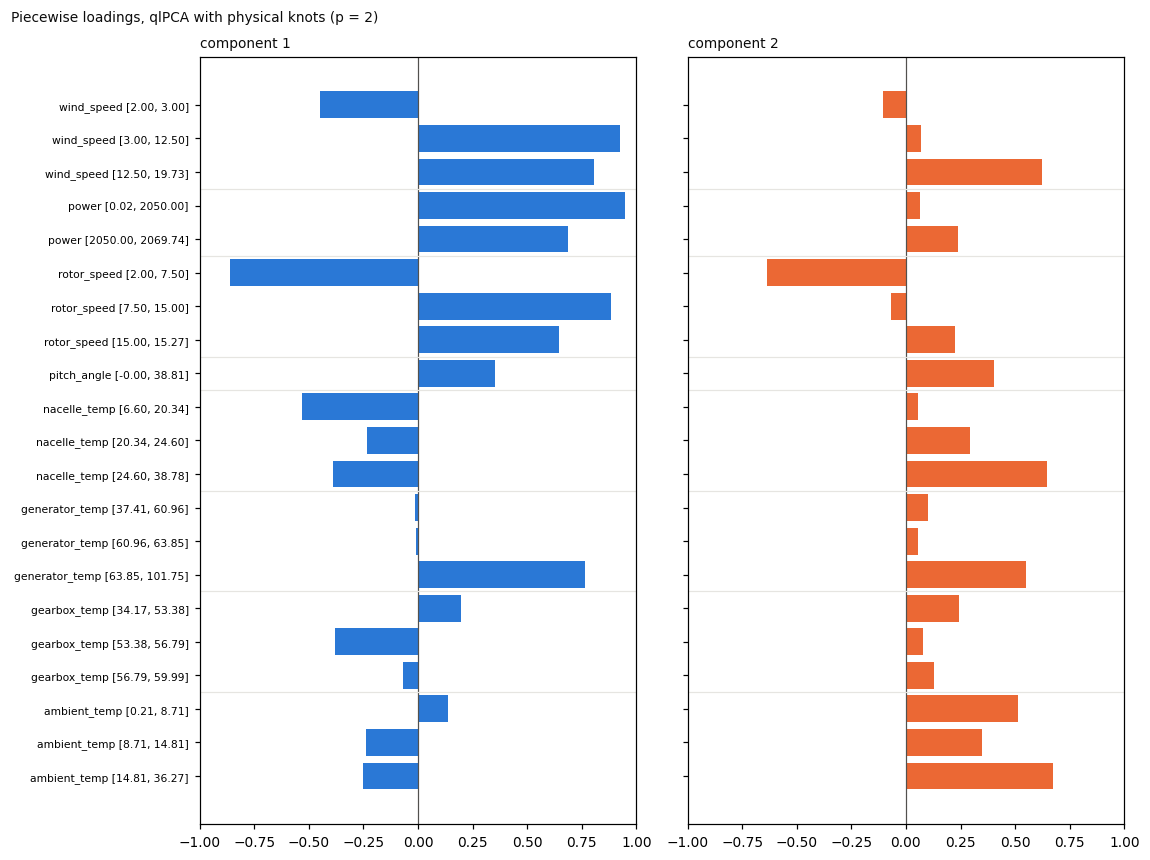

In [13]:
lab = pl_table.variable + " " + pl_table.segment
y = np.arange(len(pl_table))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 0.32 * len(pl_table) + 1.2), sharey=True)
for ax, c, col in zip(axes, ("loading 1", "loading 2"), (BLUE, ORANGE)):
    ax.barh(y, pl_table[c], color=col)
    ax.axvline(0, color=INK2, lw=0.8)
    ax.set_xlim(-1, 1); ax.set_title(c.replace("loading", "component"), fontsize=9, loc="left")
    for b in np.flatnonzero(pl_table.variable.ne(pl_table.variable.shift()))[1:]:
        ax.axhline(b - 0.5, color=GRID, lw=0.8)
axes[0].set_yticks(y, lab, fontsize=7); axes[0].invert_yaxis()
fig.suptitle("Piecewise loadings, qlPCA with physical knots (p = 2)", fontsize=9, x=0.01, ha="left")
fig.tight_layout()
save(fig, "case_piecewise_loadings")
plt.show()

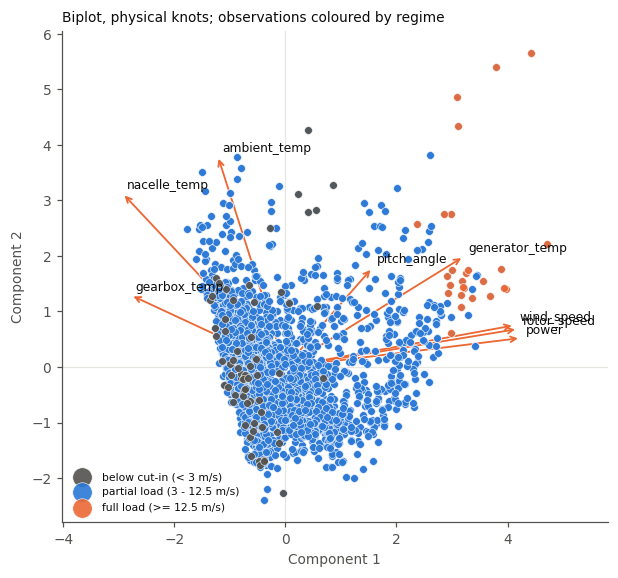

In [14]:
fig, ax = plt.subplots(figsize=(6.4, 5.8))
biplot(mf, ax=ax)
for r in REGIMES:
    sel = (regime == r).to_numpy()
    ax.scatter(mf.scores_[sel, 0], mf.scores_[sel, 1], s=26, color=RCOL[r], alpha=0.9, edgecolor="white",
               linewidth=0.4, label=r, zorder=3.5 if r == REGIMES[1] else 3.6)
ax.legend(fontsize=7, frameon=False, markerscale=2.5, loc="lower left")
ax.set_title("Biplot, physical knots; observations coloured by regime", fontsize=9, loc="left")
save(fig, "case_biplot_regimes")
plt.show()

## 6. Projection of new observations

Fit on the sampled records of January – September 2019; project October – December with `transform()`. The
`ExtrapolationWarning` is shown as issued. VAF in the projected period: (a) with the screening criterion (rows
clipped to the training range) and (b) with `transform_variables` as it is (linear extrapolation outside the
training range).

In [15]:
train = (time.dt.month <= 9).to_numpy()
Xtr, Xte = X[train], X[~train]
print(f"training records: {train.sum()} (Jan-Sep); projected records: {(~train).sum()} (Oct-Dec)")
proj = []
for name in ("PCA", "qlPCA, percentile knots", "qlPCA, physical knots"):
    m = fit(name, Xtr)
    with warnings.catch_warnings(record=True) as rec:
        warnings.simplefilter("always")
        S = m.transform(Xte)
        F_raw = m.transform_variables(Xte)
    msgs = [str(w.message) for w in rec if issubclass(w.category, ExtrapolationWarning)]
    print(f"{name}: ExtrapolationWarning: {msgs[0] if msgs else 'none issued'}")
    V = m.loadings_ / np.linalg.norm(m.loadings_, axis=0)
    proj.append({"model": name, "VAF training (in sample)": m.vaf_.sum(),
                 "VAF projected, clipped": s.oos_vaf(None, m, Xte.to_numpy(), Xtr.to_numpy()),
                 "VAF projected, linear extrapolation": 100 * np.linalg.norm(F_raw @ V) ** 2 / np.linalg.norm(F_raw) ** 2,
                 "score range training": f"[{m.scores_.min():.2f}, {m.scores_.max():.2f}]",
                 "score range projected": f"[{S.min():.2f}, {S.max():.2f}]"})
proj_table = pd.DataFrame(proj).set_index("model")
proj_table.to_csv(RES / "case_projection.csv", float_format="%.4f", lineterminator="\n")
outside = ((Xte < Xtr.min()) | (Xte > Xtr.max()))
print("projected records outside the training range, by variable:", outside.sum()[outside.sum() > 0].to_dict())
proj_table

training records: 1323 (Jan-Sep); projected records: 677 (Oct-Dec)
PCA: ExtrapolationWarning: none issued
qlPCA, percentile knots: ExtrapolationWarning: none issued


qlPCA, physical knots: ExtrapolationWarning: none issued
projected records outside the training range, by variable: {}


,VAF training (in sample),"VAF projected, clipped","VAF projected, linear extrapolation",score range training,score range projected
model,,,,,
PCA,70.4405,75.8770,75.8770,"[-5.43, 4.63]","[-3.79, 3.13]"
"qlPCA, percentile knots",78.9512,81.1250,81.1250,"[-2.43, 3.92]","[-2.02, 3.38]"
"qlPCA, physical knots",73.6164,79.1376,79.1376,"[-2.62, 5.41]","[-2.05, 4.01]"


## 7. Conclusions

Computed from the cells above.

In [16]:
v = vaf_table
L = []
L.append(f"1. Data: Kelmarsh 1, 2019, {info['records_after_filtering']} records after filtering, sample of 2000; "
         f"8 variables (generator_speed removed: correlation 1.0000 with rotor_speed).")
L.append("2. VAF with p = 2, in sample / out of sample (5 time blocks) / paired gain over PCA (se):")
for name, r in v.iterrows():
    g = "" if name == "PCA" else f" / {r['paired gain over PCA']:.2f} ({r['se (paired gain)']:.2f})"
    L.append(f"   {name}: {r['VAF in sample']:.2f} / {r['VAF out of sample']:.2f}{g}")
L.append("3. Percentile knots: descending segments hold " + ", ".join(
    f"{vv} {m.sum()} records" for vv, m in desc.items()) + f"; {int((desc['wind_speed'] & desc['power'] & desc['rotor_speed']).sum())} "
    f"records are on all three. On the wind-speed segment: median wind speed {X.wind_speed[desc['wind_speed']].median():.2f} m/s vs "
    f"{X.wind_speed[~desc['wind_speed']].median():.2f} m/s elsewhere; median power {X.power[desc['wind_speed']].median():.0f} vs "
    f"{X.power[~desc['wind_speed']].median():.0f} kW; median rotor speed {X.rotor_speed[desc['wind_speed']].median():.2f} vs "
    f"{X.rotor_speed[~desc['wind_speed']].median():.2f} rpm.")
neg = [f"{vv} {pl_f[j]['edges'][k]:.2f}-{pl_f[j]['edges'][k + 1]:.2f}" for j, vv in enumerate(VARS)
       for k, sg in enumerate(pl_f[j]['slope_sign']) if sg < 0]
L.append("4. Physical knots: segments with a decreasing transformation: " + (", ".join(neg) if neg else "none") + ".")
w = pl_table[pl_table.variable == "wind_speed"]
L.append("5. Piecewise loadings of wind speed by regime (component 1, component 2; n): " + "; ".join(
    f"{r.segment}: {r['loading 1']:.2f}, {r['loading 2']:.2f}; n = {r.n}" for _, r in w.iterrows()) + ".")
pt = proj_table
L.append("6. Projection Oct-Dec from a Jan-Sep fit, VAF clipped / linear extrapolation: " + "; ".join(
    f"{k}: {r['VAF projected, clipped']:.2f} / {r['VAF projected, linear extrapolation']:.2f}" for k, r in pt.iterrows()) + ".")
L.append(f"   Projected records outside the training range: {int(outside.to_numpy().sum())}; ExtrapolationWarning issued: "
         f"{'yes' if outside.to_numpy().any() else 'no'}.")
L.append("8. Coverage: March 2019 has no records after filtering; two 'Oil filter gear choked' Warning events of "
         "38 and 42 days (2019-02-24 to 2019-04-04 and 2019-04-09 to 2019-05-21) are removed by the filtering rule.")
L.append("9. Pitch angle: no regime value other than 0 deg (the data minimum) is given by the sources, so the "
         "physical-knot model has no interior knot for it.")
print("\n".join(L))

1. Data: Kelmarsh 1, 2019, 36890 records after filtering, sample of 2000; 8 variables (generator_speed removed: correlation 1.0000 with rotor_speed).
2. VAF with p = 2, in sample / out of sample (5 time blocks) / paired gain over PCA (se):
   PCA: 70.75 / 71.04
   qlPCA, percentile knots: 79.60 / 79.52 / 8.47 (1.77)
   qlPCA, percentile knots, monotone: 77.32 / 76.74 / 5.69 (0.70)
   qlPCA, physical knots: 74.30 / 74.01 / 2.96 (0.83)
   qlPCA, physical knots, monotone: 73.89 / 73.61 / 2.57 (0.73)
3. Percentile knots: descending segments hold wind_speed 660 records, power 660 records, rotor_speed 659 records; 617 records are on all three. On the wind-speed segment: median wind speed 4.35 m/s vs 7.26 m/s elsewhere; median power 151 vs 808 kW; median rotor speed 8.49 vs 13.36 rpm.
4. Physical knots: segments with a decreasing transformation: wind_speed 2.00-3.00, rotor_speed 2.00-7.50.
5. Piecewise loadings of wind speed by regime (component 1, component 2; n): [2.00, 3.00]: -0.45, -0.10;

### References

* Lavado, N. & Calapez, T. (2011). Principal Components Analysis with Spline Optimal Transformations for Continuous
  Data. *IAENG International Journal of Applied Mathematics*, 41(4), 367–375. (`lavado2011ijam`)
* Lavado, N. (2012). *Extensões via splines da Análise em Componentes Principais*. PhD thesis, ISCTE-IUL. (`lavado2012phd`)
* Plumley, C. & Takeuchi, R. *Kelmarsh wind farm data*. Zenodo, doi:10.5281/zenodo.16807551 (concept
  doi:10.5281/zenodo.5841833), CC-BY-4.0. (`plumley2025kelmarsh`)
* Senvion. *MM92 technical data*, senvion.com product page, archived 2020-04-02 (Internet Archive). (`senvion2020mm92`)